<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>SQL Project Case Study — Solved<br></h3></center>

# Introduction
Complete SQL answers and execution results for the 10 questions in the supplied case study.

- **Table used**: `orders(customer_id, order_date, item, quantity, price)`
- **Note**: The queries use SQLite-compatible date filtering for Question 2. For MySQL, the month filter can be written as `MONTH(order_date) = 12`.


In [1]:
# Setup: In-Memory SQLite Connection
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 4.5)

conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

print("Connected to SQLite successfully!")


Connected to SQLite successfully!


---
## Schema & Data Ingestion


In [2]:
# DDL: Create Table
cursor.execute('''
CREATE TABLE orders (
    customer_id INT,
    order_date DATE,
    item VARCHAR(100),
    quantity INT,
    price DECIMAL(10, 2)
);
''')

# DML: Insert Data
cursor.execute('''
INSERT INTO orders (customer_id, order_date, item, quantity, price)
VALUES
    (10330, '1999-06-30', 'Pogo stick', 1, 28.00),
    (10101, '1999-06-30', 'Raft', 1, 58.00),
    (10298, '1999-07-01', 'Skateboard', 1, 33.00),
    (10101, '1999-07-01', 'Life Vest', 4, 125.00),
    (10299, '1999-07-06', 'Parachute', 1, 1250.00),
    (10339, '1999-07-27', 'Umbrella', 1, 4.50),
    (10449, '1999-08-13', 'Unicycle', 1, 180.79),
    (10439, '1999-08-14', 'Ski Poles', 2, 25.50),
    (10101, '1999-08-18', 'Rain Coat', 1, 18.30),
    (10449, '1999-09-01', 'Snow Shoes', 1, 45.00),
    (10439, '1999-09-18', 'Tent', 1, 88.00),
    (10298, '1999-09-19', 'Lantern', 2, 29.00),
    (10410, '1999-10-28', 'Sleeping Bag', 1, 89.22),
    (10438, '1999-11-01', 'Umbrella', 1, 6.75),
    (10438, '1999-11-02', 'Pillow', 1, 8.50),
    (10298, '1999-12-01', 'Helmet', 1, 22.00),
    (10449, '1999-12-15', 'Bicycle', 1, 380.50),
    (10449, '1999-12-22', 'Canoe', 1, 280.00),
    (10101, '1999-12-30', 'Hoola Hoop', 3, 14.75),
    (10330, '2000-01-01', 'Flashlight', 4, 28.00),
    (10101, '2000-01-02', 'Lantern', 1, 16.00),
    (10299, '2000-01-18', 'Inflatable Mattress', 1, 38.00),
    (10438, '2000-01-18', 'Tent', 1, 79.99),
    (10413, '2000-01-19', 'Lawnchair', 4, 32.00),
    (10410, '2000-01-30', 'Unicycle', 1, 192.50),
    (10315, '2000-02-02', 'Compass', 1, 8.00),
    (10449, '2000-02-29', 'Flashlight', 1, 4.50),
    (10101, '2000-03-08', 'Sleeping Bag', 2, 88.70),
    (10298, '2000-03-18', 'Pocket Knife', 1, 22.38),
    (10449, '2000-03-19', 'Canoe paddle', 2, 40.00),
    (10298, '2000-04-01', 'Ear Muffs', 1, 12.50),
    (10330, '2000-04-19', 'Shovel', 1, 16.75);
''')
conn.commit()

df_orders = pd.read_sql_query("SELECT * FROM orders;", conn)
print(f"Loaded {len(df_orders)} records.")
df_orders.head()


Loaded 32 records.


,customer_id,order_date,item,quantity,price
0,10330,1999-06-30,Pogo stick,1,28.0
1,10101,1999-06-30,Raft,1,58.0
2,10298,1999-07-01,Skateboard,1,33.0
3,10101,1999-07-01,Life Vest,4,125.0
4,10299,1999-07-06,Parachute,1,1250.0


---
## 1. List all items purchased by customer 10449.


In [3]:
q1 = '''
SELECT item 
FROM orders 
WHERE customer_id = 10449 
ORDER BY order_date;
'''
pd.read_sql_query(q1, conn)


,item
0,Unicycle
1,Snow Shoes
2,Bicycle
3,Canoe
4,Flashlight
5,Canoe paddle


**Result / explanation:** Items: Unicycle, Snow Shoes, Bicycle, Canoe, Flashlight, Canoe paddle.

---
## 2. Find the average price of items ordered in December.


In [4]:
q2 = '''
SELECT ROUND(AVG(price), 2) AS average_price
FROM orders
WHERE strftime('%m', order_date) = '12';
'''
pd.read_sql_query(q2, conn)


,average_price
0,174.31


**Result / explanation:** Average price: 174.31. (December prices: 22.00, 380.50, 280.00, 14.75; sum is 697.25 / 4 = 174.31).

---
## 3. Find the lowest price among all tents.


In [5]:
q3 = '''
SELECT MIN(price) AS lowest_tent_price
FROM orders
WHERE item = 'Tent';
'''
pd.read_sql_query(q3, conn)


,lowest_tent_price
0,79.99


**Result / explanation:** Lowest tent price: 79.99.

---
## 4. Show each item with its maximum and minimum recorded price.


In [6]:
q4 = '''
SELECT item, 
       MAX(price) AS maximum_price, 
       MIN(price) AS minimum_price
FROM orders
GROUP BY item
ORDER BY item;
'''
pd.read_sql_query(q4, conn)


,item,maximum_price,minimum_price
0,Bicycle,380.50,380.50
1,Canoe,280.00,280.00
2,Canoe paddle,40.00,40.00
3,Compass,8.00,8.00
4,Ear Muffs,12.50,12.50
5,Flashlight,28.00,4.50
6,Helmet,22.00,22.00
7,Hoola Hoop,14.75,14.75
8,Inflatable Mattress,38.00,38.00
9,Lantern,29.00,16.00


**Result / explanation:** Returns one row per item, with its maximum and minimum price. Items appearing once have the same maximum and minimum.

---
## 5. Show items whose maximum recorded price is greater than 190.00.


In [7]:
q5 = '''
SELECT item, MAX(price) AS maximum_price
FROM orders
GROUP BY item
HAVING MAX(price) > 190.00
ORDER BY maximum_price DESC;
'''
pd.read_sql_query(q5, conn)


,item,maximum_price
0,Parachute,1250.0
1,Bicycle,380.5
2,Canoe,280.0
3,Unicycle,192.5


**Result / explanation:** Qualifying items: Parachute (1250.00), Bicycle (380.50), Canoe (280.00), Unicycle (192.50).

---
## 6. List items priced above 10.00, sorted by price in ascending order.


In [8]:
q6 = '''
SELECT item, price
FROM orders
WHERE price > 10.00
ORDER BY price ASC;
'''
pd.read_sql_query(q6, conn)


,item,price
0,Ear Muffs,12.50
1,Hoola Hoop,14.75
2,Lantern,16.00
3,Shovel,16.75
4,Rain Coat,18.30
5,Helmet,22.00
6,Pocket Knife,22.38
7,Ski Poles,25.50
8,Pogo stick,28.00
9,Flashlight,28.00


**Result / explanation:** Returns all matching item/price rows from lowest to highest price (27 rows).

---
## 7. Show customer ID, order date, and item, excluding Snow Shoes and Ear Muffs.


In [9]:
q7 = '''
SELECT customer_id, order_date, item
FROM orders
WHERE item NOT IN ('Snow Shoes', 'Ear Muffs')
ORDER BY order_date;
'''
pd.read_sql_query(q7, conn)


,customer_id,order_date,item
0,10330,1999-06-30,Pogo stick
1,10101,1999-06-30,Raft
2,10298,1999-07-01,Skateboard
3,10101,1999-07-01,Life Vest
4,10299,1999-07-06,Parachute
5,10339,1999-07-27,Umbrella
6,10449,1999-08-13,Unicycle
7,10439,1999-08-14,Ski Poles
8,10101,1999-08-18,Rain Coat
9,10439,1999-09-18,Tent


**Result / explanation:** Returns all rows except those for Snow Shoes and Ear Muffs (30 rows returned).

---
## 8. Show items and prices for items whose names start with S or P.


In [10]:
q8 = '''
SELECT item, price
FROM orders
WHERE item LIKE 'S%' OR item LIKE 'P%'
ORDER BY item;
'''
pd.read_sql_query(q8, conn)


,item,price
0,Parachute,1250.00
1,Pillow,8.50
2,Pocket Knife,22.38
3,Pogo stick,28.00
4,Shovel,16.75
5,Skateboard,33.00
6,Ski Poles,25.50
7,Sleeping Bag,89.22
8,Sleeping Bag,88.70
9,Snow Shoes,45.00


**Result / explanation:** Matching item names: Pogo stick, Parachute, Pillow, Pocket Knife, Shovel, Skateboard, Ski Poles, Sleeping Bag, Snow Shoes.

---
## 9. Show order date, item, and price for prices from 10.00 through 80.00.


In [11]:
q9 = '''
SELECT order_date, item, price
FROM orders
WHERE price BETWEEN 10.00 AND 80.00
ORDER BY price ASC;
'''
pd.read_sql_query(q9, conn)


,order_date,item,price
0,2000-04-01,Ear Muffs,12.50
1,1999-12-30,Hoola Hoop,14.75
2,2000-01-02,Lantern,16.00
3,2000-04-19,Shovel,16.75
4,1999-08-18,Rain Coat,18.30
5,1999-12-01,Helmet,22.00
6,2000-03-18,Pocket Knife,22.38
7,1999-08-14,Ski Poles,25.50
8,1999-06-30,Pogo stick,28.00
9,2000-01-01,Flashlight,28.00


**Result / explanation:** `BETWEEN` includes both endpoints (10.00 and 80.00). 18 rows returned.

---
## 10. Calculate the per-unit price for each item.


In [12]:
q10 = '''
SELECT item,
       ROUND(SUM(price) / SUM(quantity), 2) AS unit_price
FROM orders
GROUP BY item
ORDER BY unit_price DESC;
'''
pd.read_sql_query(q10, conn)


,item,unit_price
0,Parachute,1250.00
1,Bicycle,380.50
2,Canoe,280.00
3,Unicycle,186.64
4,Tent,84.00
5,Sleeping Bag,59.31
6,Raft,58.00
7,Snow Shoes,45.00
8,Inflatable Mattress,38.00
9,Skateboard,33.00


**Result / explanation:** Uses total recorded price divided by total quantity for each item. This follows the approach in the supplied case study.

---
## Important Corrections
- **Question 1** asks for the items, so the answer selects `item` rather than every column. Use `SELECT *` if all order details are required.
- **Question 2** filters the month using the date function (`strftime('%m', order_date) = '12'` or `MONTH(order_date) = 12`), which is more reliable than matching a date string with `LIKE`.
- **Question 8** says names start with S or P, so the correct condition is `LIKE 'S%' OR LIKE 'P%'`. The original condition searched for both letters anywhere in the name (`LIKE '%S%' AND LIKE '%P%'`).
- **Question 10** retains the supplied case study's calculation: `SUM(price) / SUM(quantity)`, grouped by item.


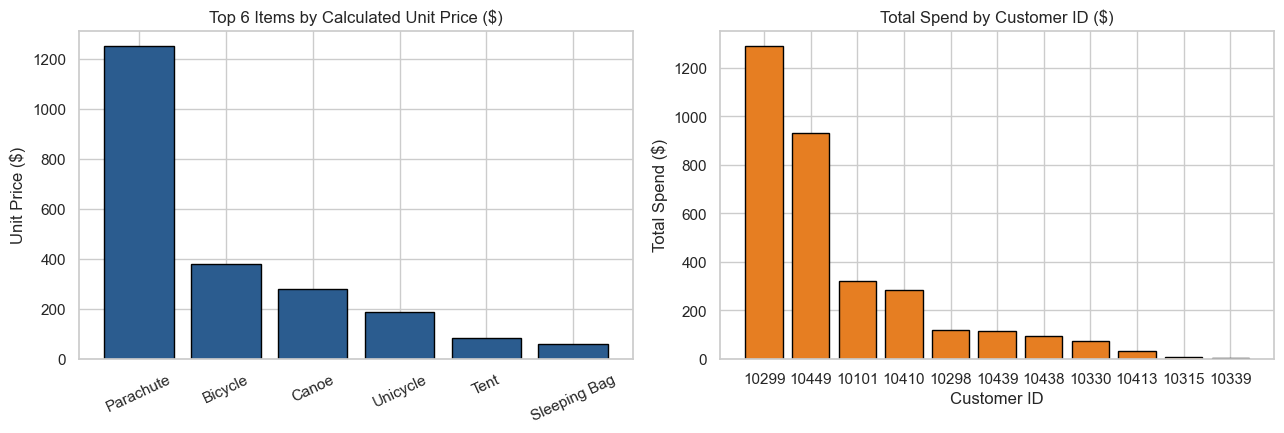

In [13]:
# Visual Summary: Unit Prices & Top Customer Spenders
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Top items by unit price
top_unit = pd.read_sql_query('''
    SELECT item, ROUND(SUM(price)/SUM(quantity), 2) AS unit_price 
    FROM orders 
    GROUP BY item 
    ORDER BY unit_price DESC 
    LIMIT 6;
''', conn)
axes[0].bar(top_unit['item'], top_unit['unit_price'], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Top 6 Items by Calculated Unit Price ($)')
axes[0].set_ylabel('Unit Price ($)')
axes[0].tick_params(axis='x', rotation=25)

# Customer spend
cust_spend = pd.read_sql_query('''
    SELECT customer_id, ROUND(SUM(price), 2) AS total_spent 
    FROM orders 
    GROUP BY customer_id 
    ORDER BY total_spent DESC;
''', conn)
axes[1].bar(cust_spend['customer_id'].astype(str), cust_spend['total_spent'], color='#e67e22', edgecolor='black')
axes[1].set_title('Total Spend by Customer ID ($)')
axes[1].set_xlabel('Customer ID')
axes[1].set_ylabel('Total Spend ($)')

plt.tight_layout()
plt.show()
